In [4]:
!pip install torch seaborn scipy pywt

ERROR: Could not find a version that satisfies the requirement pywt (from versions: none)

[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
ERROR: No matching distribution found for pywt


In [5]:
import os
import gc
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# Import our Sudo Sleep v2 SOTA pipeline
import pipeline as pl

# Ensure reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Get device (MPS for your M2 Mac)
device = pl.get_device()
print(f"Using device: {device}")
print(f"Context window: {pl.CONTEXT_WINDOW} epochs (±2 min)")
print(f"Scalar features: {pl.N_SCALAR_FEATS} dims (was 10, now +LF/HF +SpectralFlatness)")

Using device: mps
Context window: 5 epochs (±2 min)
Scalar features: 12 dims (was 10, now +LF/HF +SpectralFlatness)


In [6]:
DATA_DIR = "data" 

print("Loading PhysioNet Apnea-ECG Dataset...")
# We load only the labelled records for training/validation
df = pl.load_physionet_apnea(DATA_DIR, include_unlabelled=False)

print(f"Total Epochs Loaded: {len(df)}")
print("\nClass Distribution (0 = Normal, 1 = Apnea):")
print(df['label'].value_counts(normalize=True) * 100)

Loading PhysioNet Apnea-ECG Dataset...
Total Epochs Loaded: 17023

Class Distribution (0 = Normal, 1 = Apnea):
label
0    61.751748
1    38.248252
Name: proportion, dtype: float64


In [7]:
import time

# v2 cache — must force=True on first run to build the new 12-dim features
cache_file = "features_cache_v2.pkl"

print("Starting v2 feature extraction (12-dim: +LF/HF ratio, +Spectral Flatness)...")
t0 = time.time()

# Precompute and save the fresh 12-dimensional features
precomputed = pl.precompute_features(df, cache_path=cache_file, force=True)

print(f"Feature extraction complete in {time.time() - t0:.2f} seconds!")
print(f"Signals Shape: {precomputed['signals_3ch'].shape}")
print(f"Scalars Shape: {precomputed['scalars'].shape}")

Starting v2 feature extraction (12-dim: +LF/HF ratio, +Spectral Flatness)...


2026-03-03 07:54:52,006 | INFO | Saved features → features_cache_v2.pkl


Feature extraction complete in 137.28 seconds!
Signals Shape: (17023, 3, 6000)
Scalars Shape: (17023, 12)


In [8]:
import time

# v2 hyperparameters — lower LR for SWA stability, more epochs for SWA warmup
EPOCHS = 40
BATCH_SIZE = 128
LR = 2e-4

print("==================================================")
print(" INITIALIZING v2 5-FOLD TRAINING (SWA + Mixup)")
print("==================================================")
print(f"Target Epochs per Fold: {EPOCHS}")
print(f"Batch Size: {BATCH_SIZE}")
print(f"Learning Rate: {LR} (lower for SWA)")
print(f"SWA kicks in at: epoch {int(EPOCHS * 0.6)}")
print(f"Mixup alpha: 0.2 | Label smoothing: 0.05")
print()

start_time = time.time()

# Train the model — now uses TemporalContextDataset + SWA under the hood
ensemble_models, metrics = pl.train_model(
    df=df,
    precomputed=precomputed,
    cache_path=cache_file,
    n_folds=5,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    lr=LR,
    swa_start_frac=0.6,
    mixup_alpha=0.2,
    label_smooth=0.05,
    device=device
)

elapsed_time = time.time() - start_time
minutes = int(elapsed_time // 60)
seconds = int(elapsed_time % 60)

print("\n==================================================")
print(f"TRAINING COMPLETE (Time: {minutes}m {seconds}s)")
print("==================================================")
print(f"Mean 5-Fold AUC:       {metrics['mean_auc']:.4f} ± {metrics['std_auc']:.4f}")
print(f"Out-of-Fold (OOF) AUC: {metrics['oof_auc']:.4f}")
print("==================================================")

# Save the full SWA ensemble
pl.save_ensemble(ensemble_models, "sudo_sleep_ensemble_v2.pt")
print("\nSaved all 5 SWA models to 'sudo_sleep_ensemble_v2.pt'")
print("Ready for Streamlit dashboard integration!")

 INITIALIZING v2 5-FOLD TRAINING (SWA + Mixup)
Target Epochs per Fold: 40
Batch Size: 128
Learning Rate: 0.0002 (lower for SWA)
SWA kicks in at: epoch 24
Mixup alpha: 0.2 | Label smoothing: 0.05



2026-03-03 07:54:56,828 | INFO | ── FOLD 1/5 ──
2026-03-03 07:54:57,271 | INFO |    pos_weight = 1.67  (pos=5089, neg=8519)
2026-03-03 07:56:17,476 | INFO |   Fold 1 Ep 01/40 | AUC 0.4557 | patience 0/10
2026-03-03 07:57:26,799 | INFO |   Fold 1 Ep 02/40 | AUC 0.4539 | patience 0/10
2026-03-03 07:58:36,425 | INFO |   Fold 1 Ep 03/40 | AUC 0.4633 | patience 1/10
2026-03-03 07:59:44,983 | INFO |   Fold 1 Ep 04/40 | AUC 0.3900 | patience 0/10
2026-03-03 08:00:54,063 | INFO |   Fold 1 Ep 05/40 | AUC 0.3783 | patience 1/10
2026-03-03 08:02:06,391 | INFO |   Fold 1 Ep 06/40 | AUC 0.4244 | patience 2/10
2026-03-03 08:03:16,891 | INFO |   Fold 1 Ep 07/40 | AUC 0.5194 | patience 3/10
2026-03-03 08:04:26,661 | INFO |   Fold 1 Ep 08/40 | AUC 0.5304 | patience 0/10
2026-03-03 08:05:36,254 | INFO |   Fold 1 Ep 09/40 | AUC 0.4679 | patience 0/10
2026-03-03 08:06:46,001 | INFO |   Fold 1 Ep 10/40 | AUC 0.4746 | patience 1/10
2026-03-03 08:07:55,680 | INFO |   Fold 1 Ep 11/40 | AUC 0.6322 | patience 2


TRAINING COMPLETE (Time: 165m 33s)
Mean 5-Fold AUC:       0.8110 ± 0.0366
Out-of-Fold (OOF) AUC: 0.6011


2026-03-03 10:40:25,843 | INFO | Saved 5 models → sudo_sleep_ensemble_v2.pt



Saved all 5 SWA models to 'sudo_sleep_ensemble_v2.pt'
Ready for Streamlit dashboard integration!


Running full dataset inference for final evaluation...

--- Final Classification Report ---
              precision    recall  f1-score   support

      Normal       0.62      1.00      0.76     10512
       Apnea       0.00      0.00      0.00      6511

    accuracy                           0.62     17023
   macro avg       0.31      0.50      0.38     17023
weighted avg       0.38      0.62      0.47     17023



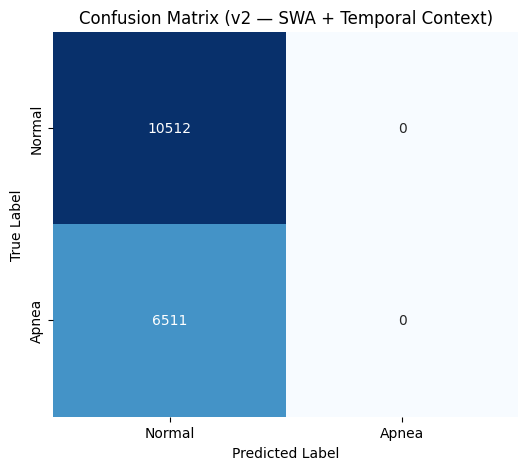

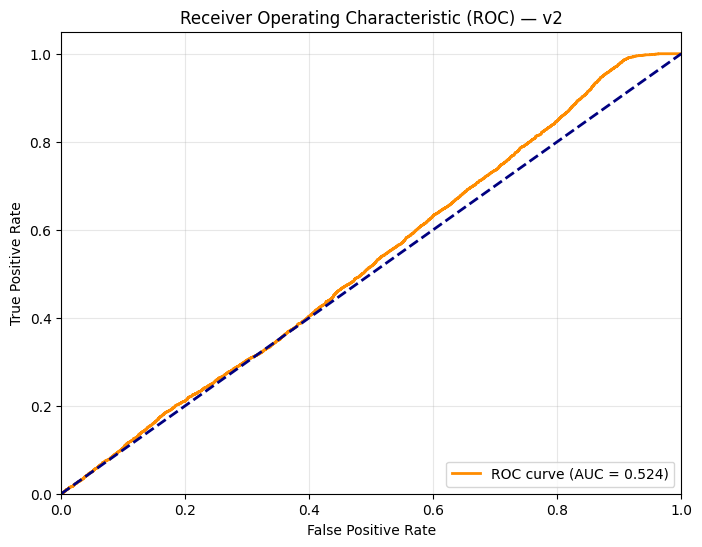

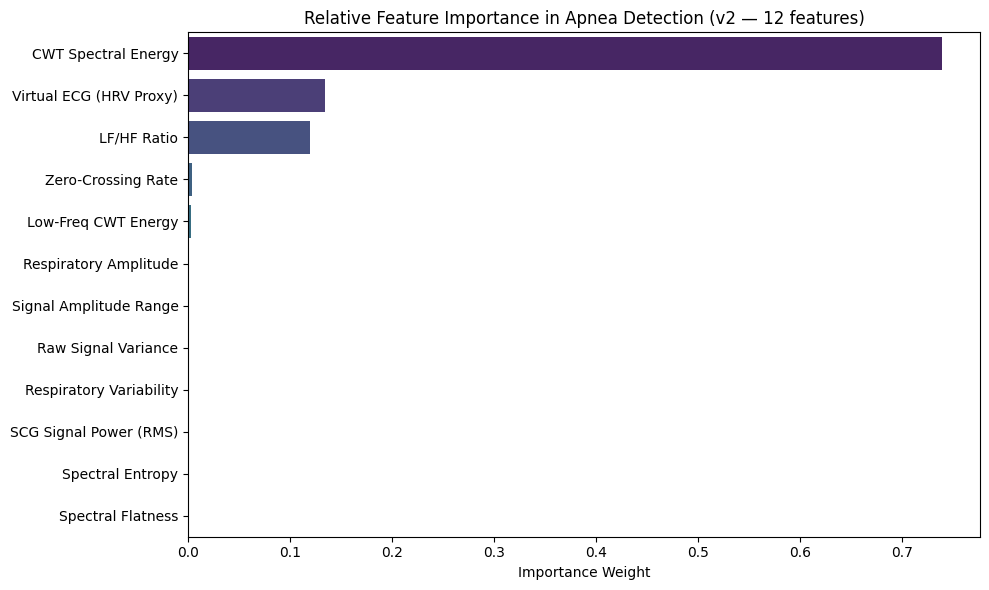

In [9]:
print("Running full dataset inference for final evaluation...")

# Run the inference engine using our freshly trained ensemble
inference_results = pl.run_inference(
    df=df,
    model=ensemble_models,
    precomputed=precomputed,
    device=device
)

true_labels = precomputed['labels']
pred_labels = inference_results['predictions']
pred_probs = inference_results['probabilities']

# 1. Classification Report
print("\n--- Final Classification Report ---")
print(classification_report(true_labels, pred_labels, target_names=["Normal", "Apnea"]))

# 2. Confusion Matrix
cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
            xticklabels=["Normal", "Apnea"], yticklabels=["Normal", "Apnea"])
plt.title('Confusion Matrix (v2 — SWA + Temporal Context)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# 3. ROC Curve Plot
fpr, tpr, _ = roc_curve(true_labels, pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) — v2')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# 4. SHAP Feature Importance Plot (now includes LF/HF Ratio + Spectral Flatness)
importances = inference_results['shap_importances']
plt.figure(figsize=(10, 6))
sns.barplot(x=list(importances.values()), y=list(importances.keys()), palette="viridis")
plt.title("Relative Feature Importance in Apnea Detection (v2 — 12 features)")
plt.xlabel("Importance Weight")
plt.tight_layout()
plt.show()